# Hotel complaint intelligence
**BIT4453 · CRISP-DM assessment**

Use **Runtime → Run all** in Google Colab. Upload `colab-project.zip` when prompted. Colab owns preparation, training, tuning and all research figures. The Streamlit application consumes the frozen artifacts. The supplied annotation pass is machine-assisted and provisional. Set `VERIFIED=True` only after review.

In [1]:
from pathlib import Path
import sys, os, zipfile
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not Path('hotel/nlp.py').exists():
        from google.colab import files
        uploads = files.upload()
        archive = next(name for name in uploads if name.endswith('.zip'))
        with zipfile.ZipFile(archive) as z:
            z.extractall('.')
    %pip -q install scikit-learn==1.9.0 nltk==3.10.4 pandas matplotlib openpyxl joblib
ROOT = Path.cwd()
if ROOT.name == 'research':
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import nltk, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from hotel import nlp
from research.prepare import prepare
from research.train import train
from nltk.stem import PorterStemmer, WordNetLemmatizer
nltk.data.path.insert(0, str(ROOT/'.runtime/nltk_data'))
try:
    nltk.data.find('corpora/wordnet.zip')
except LookupError:
    nltk.download('wordnet', download_dir=str(ROOT/'.runtime/nltk_data'), raise_on_error=True)
VERIFIED = False
plt.rcParams.update({'figure.figsize': (9, 3.5), 'axes.spines.top':False, 'axes.spines.right':False})

## 1. Business understanding · 10%
Front-desk staff receive long, mixed-topic reviews alongside direct repair requests. Manually scanning each message delays assignment and can bury a hazard in otherwise positive feedback. Predict operational urgency and department independently. Staff inspect the evidence, maintenance receives an actionable ticket, and guests track the result.

**Targets set before interpretation:** held-out macro F1 ≥ 0.80 for each target and warm p95 inference <100 ms per complaint. Report critical recall separately. Safety review is required when hazards appear or no terms match. Timing covers preprocessing, vectorization, both estimators and evidence construction, excluding network and storage.

## 2. Data understanding · 10%
Ping Li (2026), *Online review dataset from Agoda and Trip.com for tourist hotels in Taipei*, DOI 10.17632/z47pkh4x95.1, CC BY 4.0. The publisher reports 19,728 reviews from 32 hotels. The supervised sample is deliberately enriched for operational issues. Its class proportions do not estimate hotel incident prevalence. Five departments and four priorities are defined in the annotation guide. Ratings are excluded from labeling and features.

1,045 sampled records; 0 marked human-reviewed.


department,Front Desk,Guest Relations,Housekeeping,Maintenance,Marketing
urgency,,,,,
Critical,8,0,0,0,0
Low,0,240,0,0,240
Moderate,43,93,240,12,0
Urgent,0,0,0,169,0


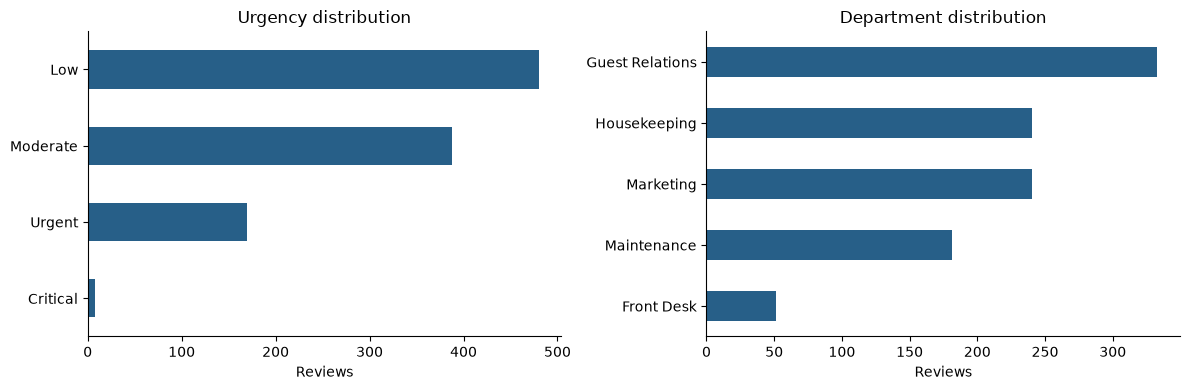

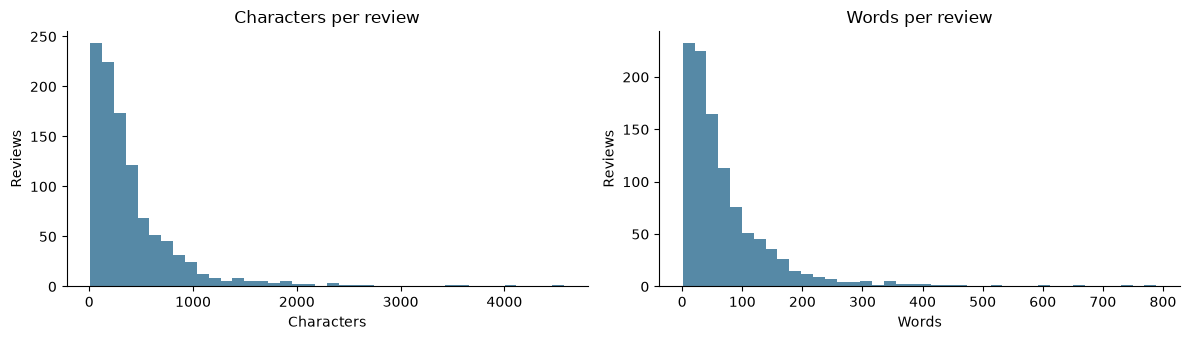

URL 0 matches


,review_id,text


HTML 0 matches


,review_id,text


Special characters 378 matches


,review_id,text
2,A8242,Pluses\n\nIt is my favorite hotel in all of As...


Informal spelling 12 matches


C:\Users\hp\AppData\Local\Temp\ipykernel_36848\3952009831.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hits=df[df.text.str.contains(pattern,case=False,regex=True)]


,review_id,text
16,T03112,Stayed in this so-called 5-star hotel for 3 ni...


In [2]:
df = pd.read_csv('data/reviews.csv') if Path('data/reviews.csv').exists() else prepare()
print(f'{len(df):,} sampled records; {df.reviewed.sum()} marked human-reviewed.')
display(df.groupby(['urgency','department']).size().unstack(fill_value=0))
fig, ax = plt.subplots(1,2,figsize=(12,4))
for axis,col in zip(ax,['urgency','department']):
    df[col].value_counts().sort_values().plot.barh(ax=axis,color='#275f88')
    axis.set(title=col.title()+' distribution',xlabel='Reviews',ylabel='')
fig.tight_layout(); plt.show()
fig, ax = plt.subplots(1,2,figsize=(12,3.5))
for axis,values,label in zip(ax,[df.text.str.len(),df.text.str.split().str.len()],['Characters','Words']):
    axis.hist(values,bins=40,color='#5689a6')
    axis.set(xlabel=label,ylabel='Reviews',title=label+' per review')
fig.tight_layout(); plt.show()
for label,pattern in {'URL':r'https?://|www\.', 'HTML':r'<\w+[^>]*>', 'Special characters':r'[^\w\s.,!?\x27-]', 'Informal spelling':r'\b(coz|wifi|u|ya|lah)\b'}.items():
    hits=df[df.text.str.contains(pattern,case=False,regex=True)]
    print(label, len(hits), 'matches')
    display(hits[['review_id','text']].head(1))

## 3. Preparation and feature extraction · 25% · CLO1
Normalize Unicode and case, expand contractions, strip markup and URLs, mask contact details and room identifiers, then normalize whitespace. Extract the room separately for dispatch. Use word tokens so an examiner can read each influential feature. Keep negators such as *not*, *never* and *no*. Drop a small explicit list of frequent function words. English-only normalization needs evaluation before deployment in other languages.

Porter stemming reduces words mechanically and can produce fragments. WordNet lemmatization is more readable for staff explanations. Our lightweight verb-then-noun lookup can over-normalize ambiguous words, so the original text remains visible. Freeze the dictionary from training words. Unseen spellings pass through. TF-IDF discounts common terms. The grid compares single words with single words plus adjacent pairs such as *not working*.

In [3]:
sample = "The heaters in Room 305 aren't working! <b>Please</b> check https://hotel.example/help."
porter, lemma = PorterStemmer(), WordNetLemmatizer()
tokens=nlp.clean(sample).split()
print(sample, '\nCleaned:', nlp.clean(sample), '\nTokens:', tokens)
display(pd.DataFrame({'word':tokens,'Porter stem':[porter.stem(t) for t in tokens],
                      'WordNet lemma':[lemma.lemmatize(lemma.lemmatize(t,'v'),'n') for t in tokens],
                      'kept':[t not in nlp.STOP for t in tokens]}))
print('Stop list:', ', '.join(sorted(nlp.STOP)))

The heaters in Room 305 aren't working! <b>Please</b> check https://hotel.example/help. 
Cleaned: the heaters in are not working please check 
Tokens: ['the', 'heaters', 'in', 'are', 'not', 'working', 'please', 'check']


,word,Porter stem,WordNet lemma,kept
0,the,the,the,False
1,heaters,heater,heater,True
2,in,in,in,False
3,are,are,be,False
4,not,not,not,True
5,working,work,work,True
6,please,pleas,please,True
7,check,check,check,True


Stop list: a, an, and, are, at, for, from, had, has, have, i, in, is, it, my, of, on, our, that, the, this, to, was, we, were


### Human annotation checkpoint
Use the accompanying CSV as a review worksheet. For each source review, read the entire text, apply the annotation guide, correct both labels, and mark `reviewed=True`. Prioritize the rare critical class and all ambiguous rows for second review. Save the amended CSV before training. The verified assessment run enforces at least 1,000 unique reviewed records. Provisional results measure agreement with annotation rules.

## 4. Modeling · 25% · CLO3
1. **Partition first.** Preserve the original joint-stratified manifest (835 train, 210 test), text fingerprints and duplicate checks. The existing holdout has been inspected in earlier work and is a historical evaluation, not a newly unseen test.
2. **Classical comparison.** Train Logistic Regression and LinearSVC on identical original training rows and identical stratified validation folds for both urgency and department.
3. **Training-only tuning.** Use pipeline cross-validation for regularization C and unigram versus unigram/bigram TF-IDF. Fit vocabulary, IDF and any supervised term weights inside each fit. Freeze choices before scoring the test set.
4. **Separate improvement experiment.** Evaluate weighted-term logistic regression first on the original training cohort, then with 31 disjoint safety training reviews. Label both experiments explicitly so the data and algorithm effects can be distinguished. Supplemental rows enter only training folds; the 16-review safety challenge remains excluded from fitting and selection.

Choose urgency candidates using validation Critical recall ≥ 2/3 and precision ≥ .50, then macro F1. If none qualifies, maximize the lesser Critical metric, then macro F1. Choose department by validation macro F1. Report failures honestly; the 0.80 target is a benchmark, not a guaranteed result.


In [4]:
report = train(df,verified=VERIFIED)
print(report['train'], 'original training reviews +', report['urgency_extra_train'], 'additional for urgency;', report['test'], 'locked test reviews.')
for target, result in report['targets'].items():
    print(target, 'champion:',result['champion'])
    display(pd.DataFrame([{'model':r['model'],'experiment':r['experiment'],**v['parameters'],'CV macro F1':v['macro_f1']}
                         for r in result['runs'] for v in r['tuning']]))
a=nlp.analyze(nlp.EXAMPLE)
print(a['text'], '→', a['lemmas'])
for target,p in a['predictions'].items():
    print(target, p['label'], p['score_type'],round(p['score'],4),'vocabulary',p['vocabulary'])
    display(pd.DataFrame(p['features']).head(10))

835 original training reviews + 31 additional for urgency; 210 locked test reviews.
urgency champion: WeightedTermLogistic


,model,experiment,model__C,tfidf__ngram_range,CV macro F1,model__critical_bias,tfidf__min_df
0,LogisticRegression,original training cohort,0.5,"(1, 1)",0.619522,NaN,NaN
1,LogisticRegression,original training cohort,0.5,"(1, 2)",0.619889,NaN,NaN
2,LogisticRegression,original training cohort,2.0,"(1, 1)",0.630015,NaN,NaN
3,LogisticRegression,original training cohort,2.0,"(1, 2)",0.627412,NaN,NaN
4,LinearSVC,original training cohort,0.5,"(1, 1)",0.634915,NaN,NaN
5,LinearSVC,original training cohort,0.5,"(1, 2)",0.627181,NaN,NaN
6,LinearSVC,original training cohort,2.0,"(1, 1)",0.629573,NaN,NaN
7,LinearSVC,original training cohort,2.0,"(1, 2)",0.638155,NaN,NaN
8,WeightedTermLogistic,original training cohort,0.5,"(1, 1)",0.697235,0.0,2.0
9,WeightedTermLogistic,original training cohort,0.5,"(1, 2)",0.709774,0.0,2.0


department champion: LinearSVC


,model,experiment,model__C,tfidf__ngram_range,CV macro F1
0,LogisticRegression,original training cohort,0.5,"(1, 1)",0.747636
1,LogisticRegression,original training cohort,0.5,"(1, 2)",0.737184
2,LogisticRegression,original training cohort,2.0,"(1, 1)",0.754954
3,LogisticRegression,original training cohort,2.0,"(1, 2)",0.710929
4,LinearSVC,original training cohort,0.5,"(1, 1)",0.758554
5,LinearSVC,original training cohort,0.5,"(1, 2)",0.746912
6,LinearSVC,original training cohort,2.0,"(1, 1)",0.727817
7,LinearSVC,original training cohort,2.0,"(1, 2)",0.732006


The air conditioner in Room 305 is broken. → ['air', 'conditioner', 'break']
urgency Urgent Linear class score 9.8933 vocabulary 2007


,term,weight,contribution
0,break,0.606908,5.867606
1,air,0.502614,3.254407
2,conditioner,0.615664,1.135508


department Maintenance Decision margin 1.413 vocabulary 3634


,term,weight,contribution
0,break,0.606908,1.141204
1,air,0.502614,0.641322
2,conditioner,0.615664,0.253019


## 5. Evaluation and ethical reflection · 25% · CLO2 and CLO3
Report accuracy and both macro and support-weighted precision, recall and F1. Macro averaging gives rare priorities equal weight. The confusion matrix uses expected classes on rows and predictions on columns. The champion is frozen before reading these results.

### Historical before and after
The same locked test rows support historical before/after reporting. Raw classifier outputs are evaluated before operational rules. The comparison includes data augmentation, so inspect the separate original-cohort and supplemental experiments below before attributing a gain to the algorithm.


,model,macro_f1,critical_recall,critical_precision,critical_cases,critical_detected,false_critical_alerts
Before,LinearSVC,0.659804,0.0,0.0,2,0,0
After,WeightedTermLogistic,0.937736,1.0,1.0,2,2,0


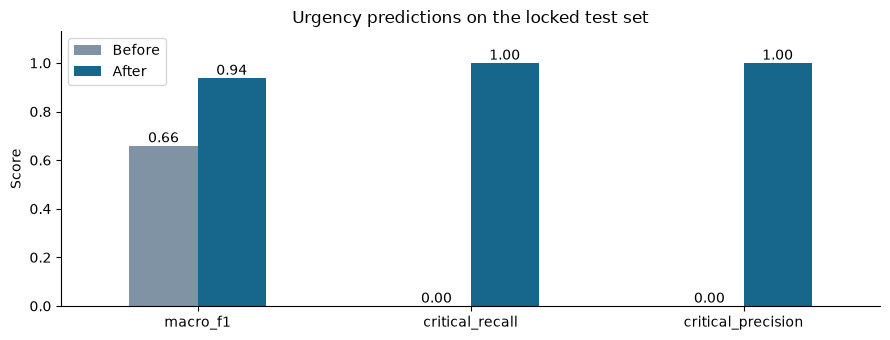

Macro F1 target: met


,source,review_id,expected,Before,After
0,agoda,A1529,Critical,Low,Critical
1,agoda,A6222,Critical,Moderate,Critical


Additional safety challenge (separate from the 210 test reviews)


,size,critical_cases,critical_detected,false_critical_alerts
Before,16,5,0,0
After,16,5,3,0


In [5]:
comparison = pd.DataFrame(report['urgency_comparison']).T
display(comparison.drop(columns='challenge'))
ax = comparison[['macro_f1','critical_recall','critical_precision']].astype(float).T.plot.bar(
    color=['#8093a4','#17668b'], rot=0, ylim=(0,1.13), title='Urgency predictions on the locked test set')
ax.set_ylabel('Score')
for bars in ax.containers: ax.bar_label(bars, fmt='%.2f')
plt.tight_layout(); plt.show()
print('Macro F1 target:', 'met' if comparison.loc['After','macro_f1'] >= 0.80 else 'missed')
pairs = pd.read_csv(ROOT/'artifacts/urgency_comparison.csv')
display(pairs[pairs.expected.eq('Critical')])
print('Additional safety challenge (separate from the 210 test reviews)')
display(pd.DataFrame(comparison.challenge.to_dict()).T)


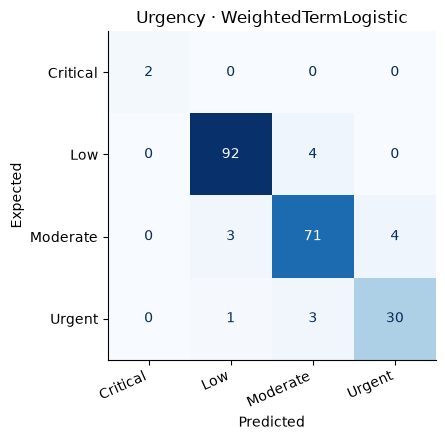

urgency macro F1 target: met


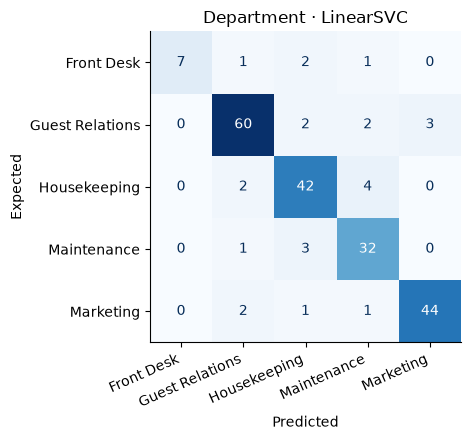

department macro F1 target: met


,target,model,experiment,accuracy,macro avg precision,macro avg recall,macro avg f1-score,weighted avg precision,weighted avg recall,weighted avg f1-score
0,urgency,LogisticRegression,original training cohort,0.876,0.902,0.780,0.820,0.877,0.876,0.876
1,urgency,LinearSVC,original training cohort,0.890,0.679,0.649,0.660,0.886,0.890,0.885
2,urgency,WeightedTermLogistic,original training cohort,0.929,0.938,0.938,0.938,0.929,0.929,0.929
3,urgency,WeightedTermLogistic,supplemental safety training,0.957,0.960,0.964,0.962,0.957,0.957,0.957
4,department,LogisticRegression,original training cohort,0.857,0.840,0.824,0.829,0.863,0.857,0.858
5,department,LinearSVC,original training cohort,0.881,0.897,0.842,0.861,0.886,0.881,0.881


Warm p95 34.97 ms. Latency target: met


In [6]:
scores=[]
for target,result in report['targets'].items():
    for run in result['runs']:
        row={'target':target,'model':run['model'],'experiment':run['experiment'],'accuracy':run['accuracy']}
        for avg in ['macro avg','weighted avg']:
            for metric in ['precision','recall','f1-score']:
                row[avg+' '+metric]=run['report'][avg][metric]
        scores.append(row)
    matrix=np.array(result['confusion']); labels=result['labels']
    fig,ax=plt.subplots(figsize=(6.8,4.5))
    image=ax.imshow(matrix,cmap='Blues')
    ax.set(xticks=range(len(labels)),yticks=range(len(labels)),xticklabels=labels,yticklabels=labels,
           xlabel='Predicted',ylabel='Expected',title=target.title()+' · '+result['champion'])
    plt.setp(ax.get_xticklabels(),rotation=24,ha='right')
    for (i,j),n in np.ndenumerate(matrix):
        ax.text(j,i,str(n),ha='center',va='center',color='white' if n>matrix.max()/2 else '#072d59')
    fig.tight_layout(); plt.show()
    best=next(r for r in result['runs'] if r['selected'])
    print(target, 'macro F1 target:', 'met' if best['report']['macro avg']['f1-score']>=.8 else 'missed')
display(pd.DataFrame(scores).round(3))
print('Warm p95',round(report['p95_ms'],2),'ms. Latency target:', 'met' if report['p95_ms']<100 else 'missed')

In [7]:
causes = {
    'A2805':'Nearby construction is mentioned but explicitly mitigated by soundproofing. A bag-of-ngrams model can still weight construction as an operational problem.',
    'A0150':'No issues and not old are negated problem cues in an otherwise positive review. The model does not fully represent negation scope.',
    'A0329':'Parking delays and a weak breakfast coexist with praise. The Low provisional label is debatable for this mixed review.',

    'A6993':'Praise dominates a brief complaint about a breakfast queue.',
    'T08464':'A dirty-room complaint is mixed with praise for service recovery.',
    'A4037':'Strong toilet smell and a room change resemble urgent maintenance.',
    'A1529':'Positive location and bed remarks surround a bathing hazard. The short safety phrase competes with the rest of the review.',
    'A6222':'The rare fall hazard is expressed through age and bathtub access. The training partition contains few critical examples.',
    'A1846':'The provisional low label follows “enjoyed”, although the writer also warns families against this room.',
    'T01424':'“Enjoyed different treatment” is a complaint in context. The weak-label rule interprets enjoyed positively.',
    'T04124':'“Not recommended” triggered a promotional keyword despite fleas, bites and pricing complaints.'
}
for e in report['errors']:
    a=nlp.analyze(e['text'])
    print(e['id'], e['target'], e['expected'], '→', e['predicted'])
    print(e['text'])
    print('Likely cause:', causes.get(e['id'],'Inspect mixed topics, unseen words and label quality.'))
    display(pd.DataFrame(a['predictions'][e['target']]['features']).head(4))

A2805 urgency Low → Moderate
It's a wonderful stay for business in a new neighborhood. There was nearby construction when I stayed there, but rooms are good at soundproofing.
Rooms are spacious with nice view. Staffs are nice that they offered me fresh fruits daily and even chocolate for good sleep at night.
Many options for food as the founder is initially in culinary industry before running this hotel: Taiwanese, Japanese, Italian,.. under your fingertips..
Likely cause: Nearby construction is mentioned but explicitly mitigated by soundproofing. A bag-of-ngrams model can still weight construction as an operational problem.


,term,weight,contribution
0,there,0.142760,0.417685
1,soundproof,0.173526,0.327384
2,wonderful,0.188366,-0.244043
3,stay,0.125707,-0.216566


T04124 urgency Low → Moderate
The room is very big and old, the shower equipment is very old, the carpet is very messy, the sofa is full of fleas and bites, it is not recommended to stay here, the house price is fickle and deceptive, they say there is only one room left, but the room is gone as soon as I place the order. There is one room, and it’s cheap, so cool😡
Likely cause: “Not recommended” triggered a promotional keyword despite fleas, bites and pricing complaints.


,term,weight,contribution
0,recommend,0.121359,-0.816636
1,there,0.170488,0.498811
2,carpet,0.187989,0.489505
3,old,0.207918,0.398200


A0150 urgency Low → Moderate
It was conveniently located in the city center, near the MRT station. I checked in after a late flight, but there were no issues at all, and all the staff were kind. They also happily assisted with restaurant reservations and luggage storage after check-out. The facilities were not particularly old, and there was a washlet as well. I highly recommend it if you don't mind not being right in front of Taipei Station.
Likely cause: No issues and not old are negated problem cues in an otherwise positive review. The model does not fully represent negation scope.


,term,weight,contribution
0,recommend,0.104494,-0.703151
1,there,0.146796,0.429493
2,not,0.153453,0.314073
3,all,0.191153,0.242716


A0329 urgency Low → Moderate
The hotel is old but is well managed with modern era renovations.
It is located at a strategic point on the subway.
Very clean place, and most importantly (No smookinge smell) in the rooms!
Breakfast "is a little weak" but meets basic needs.
Parking is chaotic, you have to wait for spaces.
But in general, I recommend it to everyone!
Likely cause: Parking delays and a weak breakfast coexist with praise. The Low provisional label is debatable for this mixed review.


,term,weight,contribution
0,recommend,0.114735,-0.772058
1,wait,0.169427,0.654971
2,but,0.176749,0.368571
3,clean,0.094182,0.290485


A6993 urgency Moderate → Low
We stayed on the 10th floor and had a beautiful city view, just as I had requested through Agoda. The hotel staff were incredibly accommodating and prepared everything as requested, which made our stay even more special.

Room:
The room was spacious enough for the four of us, including an infant. It felt cozy, was well-lit, and offered a lovely view. The beds were extremely comfortable, and the hallways were clean and nicely designed.

Cleanliness:
Even though we left our room untidy after heading out each day, the housekeeping staff did an impressive job of tidying everything up.

Internet:
The Wi-Fi was fast, which allowed me to work seamlessly at night.

Breakfast:
The breakfast was delicious, though there was a long queue depending on the time we went. We loved the wide variety of food options available.

Staff:
The staff were attentive and efficient. Whenever I requested items, they delivered them to our room in less than 10 minutes (though I assume th

,term,weight,contribution
0,recommend,0.046115,0.482150
1,work,0.063751,-0.312069
2,stay,0.080398,0.268387
3,minute,0.115299,-0.239248


### Reading the five held-out errors
A2805 describes construction mitigated by soundproofing. A0150 contains negated problem cues. A0329 mixes praise with parking delays and breakfast criticism. T04124 exposes a questionable provisional Low label despite fleas and bites. A6993 buries a breakfast queue within extensive praise. Inspect the real text and signed features above; these explanations are hypotheses, not verified causal claims.


In [8]:
pairs=[('The air conditioner is broken.','Aircon rosak lah, cannot cool.','Urgent','Maintenance'),
       ('No clean towels in the room.','Towel tak bersih lah.','Moderate','Housekeeping'),
       ('The receptionist was rude.','Reception staff rude lah.','Moderate','Guest Relations'),
       ('There is a gas leak.','Smell gas lah.','Critical','Front Desk')]
pairs += [
 ('The shower is leaking.', 'Shower leaking lah.', 'Urgent', 'Maintenance'),
 ('Please bring extra towels.', 'Can bring extra towel ah?', 'Moderate', 'Housekeeping'),
 ('The air conditioner is still not working.', 'Aircon still cannot work lah.', 'Urgent', 'Maintenance'),
 ('The room has exposed live wires.', 'Room got exposed live wires lah.', 'Critical', 'Front Desk'),
 ('The bathroom drain is blocked.', 'Bathroom drain blocked lah.', 'Urgent', 'Maintenance'),
 ('Please clean the room.', 'Tolong clean room ya.', 'Moderate', 'Housekeeping'),
 ('The shower has no hot water.', 'Shower no hot water lah.', 'Urgent', 'Maintenance'),
 ('There are sparks flying from the socket.', 'Socket got sparks flying lah.', 'Critical', 'Front Desk')]
audit=[]
for standard, informal, priority, department in pairs:
    for style,text in [('Standard',standard),('Informal',informal)]:
        a=nlp.analyze(text)
        audit.append({'style':style,'text':text,'expected urgency':priority,'model urgency':a['predictions']['urgency']['label'],
                      'expected team':department,'model team':a['predictions']['department']['label'],'final urgency':a['urgency'],
                      'matched terms':len(a['predictions']['urgency']['features'])})
audit=pd.DataFrame(audit);display(audit)
display(audit.assign(correct=audit['expected urgency']==audit['model urgency']).groupby('style').correct.mean())
print('Compare drops in matched terms and disagreements pair by pair before extending the training corpus.')
print('Probe size:', len(pairs), 'matched pairs /',len(audit),'sentences. Labels are illustrative, not independently annotated.')
for metric in ['model urgency','model team','final urgency']:
    standard=audit[audit['style']=='Standard'][metric].to_numpy()
    informal=audit[audit['style']=='Informal'][metric].to_numpy()
    print(metric, 'paired disagreements:', int((standard!=informal).sum()), '/', len(pairs))
print('This diagnostic cannot establish population fairness. Manglish, Hindi, Malay, Mandarin and Burmese speech require separate human-labeled evaluations. Translation errors are outside the English holdout metrics.')


,style,text,expected urgency,model urgency,expected team,model team,final urgency,matched terms
0,Standard,The air conditioner is broken.,Urgent,Urgent,Maintenance,Maintenance,Urgent,3
1,Informal,"Aircon rosak lah, cannot cool.",Urgent,Urgent,Maintenance,Maintenance,Urgent,3
2,Standard,No clean towels in the room.,Moderate,Moderate,Housekeeping,Housekeeping,Moderate,4
3,Informal,Towel tak bersih lah.,Moderate,Moderate,Housekeeping,Housekeeping,Moderate,1
4,Standard,The receptionist was rude.,Moderate,Moderate,Guest Relations,Guest Relations,Moderate,2
5,Informal,Reception staff rude lah.,Moderate,Moderate,Guest Relations,Guest Relations,Moderate,3
6,Standard,There is a gas leak.,Critical,Urgent,Front Desk,Maintenance,Critical,2
7,Informal,Smell gas lah.,Critical,Moderate,Front Desk,Housekeeping,Critical,1
8,Standard,The shower is leaking.,Urgent,Urgent,Maintenance,Maintenance,Urgent,2
9,Informal,Shower leaking lah.,Urgent,Urgent,Maintenance,Maintenance,Urgent,2


style
Informal    0.666667
Standard    0.666667
Name: correct, dtype: float64

Compare drops in matched terms and disagreements pair by pair before extending the training corpus.
Probe size: 12 matched pairs / 24 sentences. Labels are illustrative, not independently annotated.
model urgency paired disagreements: 2 / 12
model team paired disagreements: 2 / 12
final urgency paired disagreements: 0 / 12
This diagnostic cannot establish population fairness. Manglish, Hindi, Malay, Mandarin and Burmese speech require separate human-labeled evaluations. Translation errors are outside the English holdout metrics.


## 6. Deployment and monitoring
Export fitted pipelines, WordNet lookup, VADER lexicon, evaluation metadata and shared preprocessing together. The app deploys the selected urgency and department models behind one analysis interface. Model comparisons stay in this notebook and the report.

Wavo adds deterministic intent, clause-scoped issue states and category-based approved procedures. VADER is a sentiment heuristic, not an urgency classifier. No extraction or sentiment F1 is claimed. Rule regression examples are separate from classifier test metrics.

Demonstrate Room 305 → inspect NLP and procedure evidence → Start work → Submit outcome → guest confirms or reopens. Preserve prediction snapshots and versioned staff corrections. Transcript storage is off by default; without consent save only the necessary service record. PII patterns are removed from features, and contact details are masked in retained transcripts. Names and contextual identifiers still require careful handling.

Monitor critical misses, unrecognized vocabulary, reopened requests, staff corrections, dialect disagreements and expanded-engine latency. Review labels independently and collect a fresh final holdout before making deployment claims. Keep previous bundles for rollback.


In [9]:
import shutil
archive=shutil.make_archive(str(ROOT/'.runtime/model-export'),'zip',ROOT,'artifacts')
print('Frozen artifacts:',report['version'],archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Frozen artifacts: tfidf-v2-7b3f2e4069 C:\City_University_Fifth_Sem\Natural Language Processing\Assignments\Hotel_Service\.runtime\research-verification\.runtime\model-export.zip


### Operational deployment and independent label review
The Streamlit app deploys the selected urgency/department bundle. Plain Python services handle assignment, deadline monitoring, notifications and guest confirmation. These operational rules are not trained model predictions.
Use `research/label_review.py` to export a fresh annotation worksheet. The supplied worksheet retains all 1,045 original texts, provisional labels, partition membership and text hashes. Reviewer, UTC timestamp, corrected labels and rationale must be supplied by actual reviewers. Publish reviewed labels as a new dataset version; do not silently revise historical evaluation or tune against the locked test set.
The saved outputs in this notebook were produced by local Jupyter execution. Execute all cells in your Google Colab runtime to verify that environment. No new training or predictive scores are claimed by the operational upgrade.
